In [11]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver

In [12]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [13]:
llm = ChatOpenAI(
    model = "openai/gpt-oss-20b",
    api_key = os.getenv("GROK_API_KEY"),
    base_url = "https://api.groq.com/openai/v1",
)

In [14]:
class ChatState(TypedDict):
    # messages : str
    messages: Annotated[list[BaseMessage], add_messages]

In [15]:
def chat_node(state : ChatState) -> ChatState:
    messages = state["messages"]
    response = llm.invoke(messages).content
    return {
        "messages" : [response]
    }

In [16]:
checkpointer = InMemorySaver()

graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)

graph.add_edge(START, "chat_node")
graph.add_edge("chat_node", END)

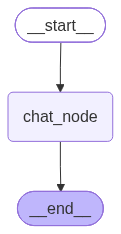

In [17]:
chatbot = graph.compile(checkpointer = checkpointer)
chatbot

In [18]:
thread_id = 1

while True:
    user_query = input("Type here: ")
    print("User:", user_query)

    if user_query == "exit":
        break

    config = {
        "configurable" : {
            'thread_id' : thread_id
        }
    }
    
    response = chatbot.invoke(
        {
            'messages' : [
                HumanMessage(content = user_query)
            ]
        },
        config = config
    )

    print("AI:", response['messages'][-1].content)

User: Hello
AI: Hello! How can I help you today?
User: My name is Amandeep Singh
AI: Nice to meet you, Amandeep! How can I assist you today?
User: What is my name?
AI: Your name is Amandeep Singh.
User: exit


* invoke() starts the new graph execution everytime, even if we are using add_messages it is not retaining the messages.(Without Checkpointers)

In [19]:
chatbot.get_state(config = config)

StateSnapshot(values={'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='5e269441-8160-4ce2-8bb1-9d7b6b4c1cd1'), HumanMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={}, id='e4286387-34c1-4ce9-a633-45d090ed59cd'), HumanMessage(content='My name is Amandeep Singh', additional_kwargs={}, response_metadata={}, id='5624e04c-3aa6-4fa9-b3db-c4189a59d094'), HumanMessage(content='Nice to meet you, Amandeep! How can I assist you today?', additional_kwargs={}, response_metadata={}, id='1e01a815-90ff-4d4c-bf0d-142d71417b44'), HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='98d53947-9b9c-4f67-b8e2-1729c82e86e3'), HumanMessage(content='Your name is Amandeep\u202fSingh.', additional_kwargs={}, response_metadata={}, id='e3ff1530-886a-4c69-864d-111ab732946b')]}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5596-ce58-69db-8007-ca30